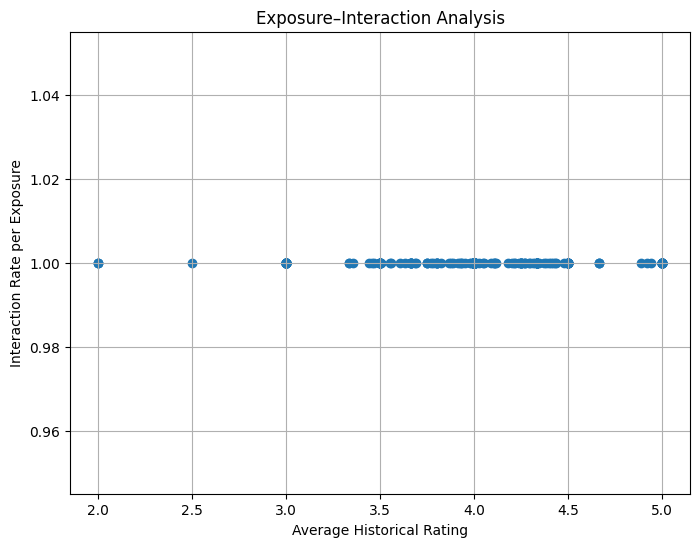

In [11]:
# %% [markdown]
# # Exposure–Interaction Feedback Loop Analysis

# %% [code]
import sqlite3
import pandas as pd
import json, os

# db_dir= "/app/db"
db_dir = "/home/abel/group-project-f25-home-alone/homealone/db"

db_path = os.path.join(db_dir, "home_alone.db")


conn = sqlite3.connect(db_path)

# %% [code]
# Load recommendations table
rec_df = pd.read_sql("SELECT * FROM kafka_recs", conn, parse_dates=['timestamp'])
# Parse JSON array of recommended_items
# rec_df = rec_df.explode(rec_df['recommended_items'].apply(json.loads))
rec_df.rename(columns={'recommended_items': 'movie_ids'}, inplace=True)
    
rec_df['movie_id'] = rec_df['movie_ids'].str.split(',')
rec_df = rec_df.explode('movie_id').drop(columns='movie_ids').reset_index(drop=True)

rec_df['timestamp'] = pd.to_datetime(rec_df['timestamp'])

# %% [code]
# Load watch history
watch_df = pd.read_sql("SELECT * FROM watch_history", conn, parse_dates=["start_time", "last_watch", "rated_at"])
watch_df['start_time'] = pd.to_datetime(watch_df['start_time'])
watch_df['last_watch'] = pd.to_datetime(watch_df['last_watch'])


# %% [code]
# Join recommendations to watch history to see if a recommended movie was watched after recommendation
merged = pd.merge(
    rec_df[['user_id', 'movie_id', 'timestamp']],
    watch_df[['user_id', 'movie_id', 'last_watch']],
    on=['user_id', 'movie_id'],
    how='left'
)

# Only consider watches after the recommendation
merged = merged[merged['last_watch'] >= merged['timestamp']]

# %% [code]
# Calculate exposure count and watch count per movie
exposure_stats = merged.groupby('movie_id').agg(
    exposures=('movie_id', 'count'),
    watches=('last_watch', 'count')
).reset_index()

# Calculate interaction rate (watches per exposure)
exposure_stats['interaction_rate'] = exposure_stats['watches'] / exposure_stats['exposures']

# %% [code]
# Sort by exposures
exposure_stats.sort_values(by='exposures', ascending=False, inplace=True)
exposure_stats.head(10)

# %% [code]
# Optional: Load ratings to compare
ratings_df = pd.read_sql("SELECT * FROM ratings", conn)

avg_ratings = ratings_df.groupby('movie_id')['rating'].mean().reset_index()
exposure_stats = exposure_stats.merge(avg_ratings, on='movie_id', how='left')

# %% [code]
# Quick analysis: interaction rate vs average rating
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
plt.scatter(exposure_stats['rating'], exposure_stats['interaction_rate'])
plt.xlabel("Average Historical Rating")
plt.ylabel("Interaction Rate per Exposure")
plt.title("Exposure–Interaction Analysis")
plt.grid(True)
plt.show()

# %% [markdown]
# **Interpretation:**
# - If movies with **low average ratings** still have high interaction rates, this suggests exposure is driving interactions.
# - A positive correlation between exposure count and interaction rate, especially for previously less-rated movies, indicates a potential **feedback loop**.
